In [1]:
import pandas as pd
import numpy as np
import pyvrp

In [2]:
data_nodos=pd.read_excel(r'datos_ejemplo_esmax.xlsx')

#10 clientes
#una planta

In [3]:
data_nodos.head(10)

,Nodo,Pedido
0,Planta Maipú,0
1,Curicó,6
2,Molina,20
3,Pichilemu,13
4,Chimbarongo,9
5,Melipilla,10
6,Calera de Tango,19
7,Puente Alto,9
8,San Bernardo,6
9,Recoleta,16


In [4]:
df_distancias=pd.read_excel(r'distancias_ejemplo_esmax.xlsx')
#distancias tomadas de google maps, de manera aproximada

In [5]:
df_distancias=df_distancias.iloc[:,1:]

In [6]:
matriz=df_distancias.to_numpy()
print(matriz)

[[  0 170 184 150 135  46  12  18   8  16   4]
 [170   0  16  92  35 145 156 164 160 183 171]
 [184  16   0 102  49 159 171 177 175 198 186]
 [150  92 102   0  97 109 142 157 148 166 153]
 [135  35  49  97   0 116 122 129 126 147 137]
 [ 46 145 159 109 116   0  43  59  47  60  50]
 [ 12 156 171 142 122  43   0  17   5  25  15]
 [ 18 164 177 157 129  59  17   0  12  18  17]
 [  8 160 175 148 126  47   5  12   0  18   9]
 [ 16 183 198 166 147  60  25  18  18   0  12]
 [  4 171 186 153 137  50  15  17   9  12   0]]


##### Creando el modelo

Se añaden los datos de la planta, los clientes, y las distancias entre todos los nodos.

In [7]:
modelo=pyvrp.Model()
modelo.add_depot(0,0, name='Planta Maipú')


In [8]:
for i in range(1,len(data_nodos['Nodo'])):
    modelo.add_client(0,0,delivery=int(data_nodos.iloc[i,1]),name=str(data_nodos.iloc[i,0]))


In [9]:
for frm_idx, frm in enumerate(modelo.locations):
    for to_idx, to in enumerate(modelo.locations):
        modelo.add_edge(frm, to, distance=matriz[frm_idx][to_idx])

También se añaden los datos de los vehículos. Estos son datos reales de vehículos extraídos de los datos compartidos desde esmax, siendo todos vehículos asociados a la Planta Maipú. Acá se identifican según el orden en que se añaden al modelo, siendo el primero 0, el segundo 1 y el tercero 2. Esto nos ayudará a comprender la solución final.

In [10]:
modelo.add_vehicle_type(capacity=20, num_available=5, start_depot=modelo.locations[0], end_depot=modelo.locations[0], name='camion_1')
modelo.add_vehicle_type(capacity=35, num_available=1, start_depot=modelo.locations[0], end_depot=modelo.locations[0], name='camion_2')
modelo.add_vehicle_type(capacity=27, num_available=10, start_depot=modelo.locations[0], end_depot=modelo.locations[0], name='camion_3')

##### La solución
Se obtiene la solución del modelo según el algoritmo. Se explica más abajo.


In [11]:
from pyvrp.stop import MaxRuntime
res = modelo.solve( stop = MaxRuntime (1) , seed = 3)

PyVRP v0.11.3

Solving an instance with:
    1 depot
    10 clients
    16 vehicles (3 vehicle types)

                  |       Feasible        |      Infeasible
    Iters    Time |   #      Avg     Best |   #      Avg     Best
H     500      1s |  32      832      760 |  55      729      681

Search terminated in 1.00s after 624 iterations.
Best-found solution has cost 760.

Solution results
    # routes: 5
     # trips: 5
   # clients: 10
   objective: 760
    distance: 760
    duration: 0
# iterations: 624
    run-time: 1.00 seconds



In [12]:
print(res)

Solution results
    # routes: 5
     # trips: 5
   # clients: 10
   objective: 760
    distance: 760
    duration: 0
# iterations: 624
    run-time: 1.00 seconds

Routes
------
Route #1: 4 1 2
Route #2: 9 7
Route #3: 8 6
Route #4: 3 5
Route #5: 10



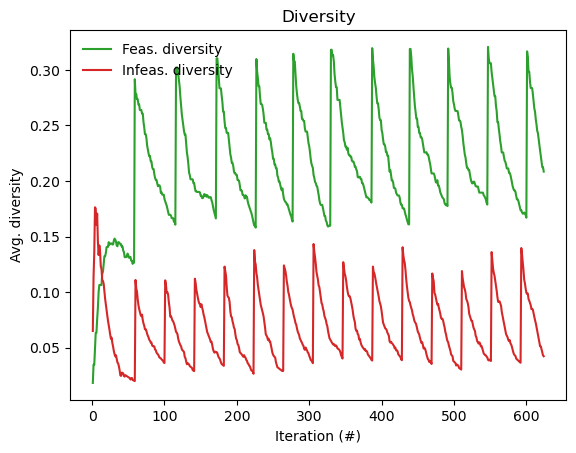

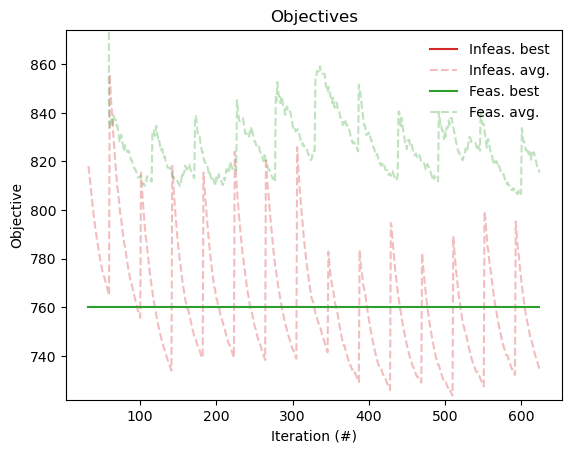

In [13]:
from pyvrp.plotting import plot_diversity, plot_objectives

plot_diversity(res)
plot_objectives(res)

In [14]:
best=res.best
rutas=best.routes()
num_rutas=best.num_routes()

In [15]:
for i in range(0,num_rutas):
    print(f' La ruta recorrida por el vehículo {rutas[i].vehicle_type()} son los clientes {rutas[i]}')

 La ruta recorrida por el vehículo 1 son los clientes 4 1 2
 La ruta recorrida por el vehículo 2 son los clientes 9 7
 La ruta recorrida por el vehículo 2 son los clientes 8 6
 La ruta recorrida por el vehículo 2 son los clientes 3 5
 La ruta recorrida por el vehículo 2 son los clientes 10
